In [1]:
!pip install -q faiss-cpu rank_bm25 datasets sentence-transformers

import os, re, json, time, shutil, random, torch, faiss
import numpy as np, pandas as pd
from collections import Counter
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from transformers import pipeline

random.seed(42); np.random.seed(42); torch.manual_seed(42)
words = lambda s: re.sub(r'[^\w\s]', '', s.lower()).split()
os.makedirs("rag_outputs", exist_ok=True)

In [2]:
ds = load_dataset("rajpurkar/squad_v2", split="train")

docs_map, qas_map = {}, {}
for r in ds:
    docs_map.setdefault(r["title"], {})[r["context"]] = 1
    qas_map.setdefault(r["title"], []).append(r)

titles = [t for t, c in docs_map.items() if len(c) >= 15][:50]

docs, ctx_off = [], {}
for i, t in enumerate(titles):
    off = 0
    for c in docs_map[t]:
        ctx_off[(i, c)] = off
        off += len(c) + 2
    docs.append({"id": f"doc_{i}", "text": "\n\n".join(docs_map[t].keys())})

ans, unans = [], []
for i, t in enumerate(titles):
    for q in qas_map[t]:
        txts = q["answers"]["text"]
        item = {"id": q["id"], "doc": f"doc_{i}", "q": q["question"],
                "ans": bool(txts), "gold": txts[0] if txts else "UNANSWERABLE"}
        if txts:
            s = ctx_off[(i, q["context"])] + q["answers"]["answer_start"][0]
            item["span"] = [s, s + len(txts[0])]
        (ans if item["ans"] else unans).append(item)

random.shuffle(ans); random.shuffle(unans)
dev_set = ans[:40] + unans[:10]
test_set = ans[40:140] + unans[10:30]
print(f"Docs: {len(docs)} | Dev: {len(dev_set)} | Test: {len(test_set)}")

README.md:   0%|          | 0.00/8.92k [00:00<?, ?B/s]

squad_v2/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.4MB            

squad_v2/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

squad_v2/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 1.35MB            

squad_v2/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/130319 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/11873 [00:00<?, ? examples/s]

Docs: 50 | Dev: 50 | Test: 120


In [3]:
BASIC_SIZE, BASIC_STRIDE, MAX_CHUNK = 350, 300, 750

def basic_chunks_of(d):
    t = d["text"]
    return [{"id": f"{d['id']}_b{j}", "doc": d["id"], "start": i,
             "end": min(i + BASIC_SIZE, len(t)), "text": t[i:i + BASIC_SIZE]}
            for j, i in enumerate(range(0, len(t), BASIC_STRIDE))]

def recursive_chunks_of(d):
    out, pos, j = [], 0, 0
    def emit(p, p_start, cs, ce):
        nonlocal j
        txt = p[cs:ce].strip()
        if len(txt) > 30:
            out.append({"id": f"{d['id']}_r{j}", "doc": d["id"],
                        "start": p_start + cs, "end": p_start + ce, "text": txt}); j += 1
    for p in d["text"].split("\n\n"):
        p_start = d["text"].index(p, pos); pos = p_start + len(p)
        spans = []
        for m in re.finditer(r'[^.!?]+[.!?]*\s*', p):
            s, e = m.span()
            while e - s > MAX_CHUNK:
                spans.append((s, s + MAX_CHUNK)); s += MAX_CHUNK
            spans.append((s, e))
        cs = ce = None
        for s, e in spans:
            if cs is None: cs, ce = s, e
            elif e - cs <= MAX_CHUNK: ce = e
            else: emit(p, p_start, cs, ce); cs, ce = s, e
        if cs is not None: emit(p, p_start, cs, ce)
    return out

basic_chunks = [c for d in docs for c in basic_chunks_of(d)]
rec_chunks   = [c for d in docs for c in recursive_chunks_of(d)]

embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def make_index(chunks):
    texts = [c["text"] for c in chunks]
    embs = embedder.encode(texts, normalize_embeddings=True)
    idx = faiss.IndexFlatIP(embs.shape[1])
    idx.add(embs)
    return idx, BM25Okapi([words(t) for t in texts])

b_faiss, b_bm25 = make_index(basic_chunks)
r_faiss, r_bm25 = make_index(rec_chunks)
print(f"Basic: {len(basic_chunks)} | Recursive: {len(rec_chunks)}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Basic: 5262 | Recursive: 3429


In [4]:
llm = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", torch_dtype=torch.float16, device_map="auto")

def retrieve(query, chunks, f_idx, b_idx=None):
    _, d_ids = f_idx.search(embedder.encode([query], normalize_embeddings=True), 15)
    if not b_idx:
        top_ids = d_ids[0][:3]
    else:
        b_ids = np.argsort(b_idx.get_scores(words(query)))[::-1][:15]
        scores = {}
        for r, i in enumerate(d_ids[0]): scores[i] = scores.get(i, 0) + 1/(60+r)
        for r, i in enumerate(b_ids):    scores[i] = scores.get(i, 0) + 1/(60+r)
        top_ids = [i for i, _ in sorted(scores.items(), key=lambda x: x[1], reverse=True)[:3]]
    return [chunks[i] for i in top_ids]

def ask(question, passages):
    ctx = "\n".join([p["text"] for p in passages])
    msgs = [
        {"role": "system", "content": "Answer concisely using ONLY the context. If not in context, output ONLY: UNANSWERABLE"},
        {"role": "user", "content": f"Context:\n{ctx}\n\nQuestion: {question}"}
    ]
    return llm(msgs, max_new_tokens=30, do_sample=False)[0]["generated_text"][-1]["content"].strip()

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [5]:
def get_f1(pred, gold):
    p, g = words(pred), words(gold)
    common = sum((Counter(p) & Counter(g)).values())
    return (2 * common) / (len(p) + len(g)) if (p and g) else 0.0

get_em = lambda pred, gold: float(words(pred) == words(gold))

ABST_KEYS = ["unanswerable", "not mentioned", "no information", "cannot"]
is_abst = lambda o: any(w in o.lower() for w in ABST_KEYS)

def get_faith(pred, passages):
    p, ctx = words(pred), set(words(" ".join(x["text"] for x in passages)))
    return sum(w in ctx for w in p) / len(p) if p else 0.0

configs = [
    ("C1_Naive",     basic_chunks, b_faiss, None),
    ("C2_Hybrid",    basic_chunks, b_faiss, b_bm25),
    ("C3_Recursive", rec_chunks,   r_faiss, None),
    ("C4_Combined",  rec_chunks,   r_faiss, r_bm25),
]

summary = []
for name, chunks, f_idx, b_idx in configs:
    t0 = time.time()
    rows, recs, mrrs, ems, f1s, faiths, false_abst, absts = [], [], [], [], [], [], [], []

    for item in test_set:
        ret = retrieve(item["q"], chunks, f_idx, b_idx)
        out = ask(item["q"], ret)
        abst_flag = is_abst(out)
        rec = mrr = em = f1 = faith = abst = None

        if item["ans"]:
            s0, s1 = item["span"]
            hit = next((r + 1 for r, c in enumerate(ret)
                        if c["doc"] == item["doc"] and c["start"] < s1 and c["end"] > s0), 0)
            rec, mrr = float(hit > 0), (1.0 / hit if hit else 0.0)
            em, f1 = get_em(out, item["gold"]), get_f1(out, item["gold"])
            recs.append(rec); mrrs.append(mrr); ems.append(em); f1s.append(f1)
            false_abst.append(float(abst_flag))
            if not abst_flag:
                faith = get_faith(out, ret); faiths.append(faith)
        else:
            abst = float(abst_flag); absts.append(abst)

        rows.append({
            "condition": name, "sample_id": item["id"], "question": item["q"], "output": out,
            "gold": item["gold"], "gold_span": item.get("span"),
            "retrieved_ids": [c["id"] for c in ret], "ranks": list(range(1, len(ret) + 1)),
            "Recall@3": rec, "MRR": mrr, "EM": em, "F1": f1, "Faithfulness": faith, "Abstention": abst
        })

    pd.DataFrame(rows).to_csv(f"rag_outputs/{name}.csv", index=False)
    with open(f"rag_outputs/{name}.json", "w") as f: json.dump(rows, f, indent=2)

    summary.append({
        "Condition": name, "Chunks": len(chunks),
        "Recall@3": round(np.mean(recs)*100, 2), "MRR": round(np.mean(mrrs)*100, 2),
        "EM": round(np.mean(ems)*100, 2), "F1": round(np.mean(f1s)*100, 2),
        "Faithfulness": round(np.mean(faiths)*100, 2),
        "FalseAbst(ans)": round(np.mean(false_abst)*100, 2),
        "Abstention(unans)": round(np.mean(absts)*100, 2),
        "Time(s)": round(time.time()-t0, 1)
    })
    print(f"{name} done.")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


C1_Naive done.
C2_Hybrid done.
C3_Recursive done.
C4_Combined done.


In [6]:
config_info = {
    "seed": 42,
    "dataset": "rajpurkar/squad_v2 (train split, 50 docs with >=15 paragraphs)",
    "num_documents": len(docs),
    "dev_set_size": len(dev_set),
    "test_set_size": {"answerable": sum(i["ans"] for i in test_set),
                      "unanswerable": sum(not i["ans"] for i in test_set)},
    "embedding_model": "sentence-transformers/all-MiniLM-L6-v2 (normalized, FAISS IndexFlatIP)",
    "generation_model": "Qwen/Qwen2.5-1.5B-Instruct (fp16)",
    "top_k": 3,
    "decoding": {"do_sample": False, "max_new_tokens": 30},
    "chunking": {"basic": {"size_chars": BASIC_SIZE, "stride_chars": BASIC_STRIDE},
                 "recursive": {"max_chars": MAX_CHUNK, "split": "paragraph -> sentence packing -> hard split"}},
    "hybrid": {"bm25": "BM25Okapi, tokens=lowercase word tokens w/o punctuation",
               "fusion": "Reciprocal Rank Fusion, k=60", "candidates_per_retriever": 15},
    "gold_evidence_mapping": "chunk (same doc) overlaps gold answer character span",
    "abstention_detection_keywords": ABST_KEYS,
    "faithfulness": "lexical overlap of answer tokens with retrieved context; abstentions excluded",
    "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "system_prompt": "Answer concisely using ONLY the context. If not in context, output ONLY: UNANSWERABLE"
}
with open("rag_outputs/config_and_prompts.json", "w") as f:
    json.dump(config_info, f, indent=2)

df_sum = pd.DataFrame(summary)
df_sum.to_csv("rag_outputs/summary.csv", index=False)
with open("rag_outputs/summary.json", "w") as f: json.dump(summary, f, indent=2)

for s in summary:
    print(f"--- {s['Condition']} Metrics ---")
    print(s)
print("\n=== ALL CONDITIONS SUMMARY TABLE ===")
print(df_sum.to_string(index=False))

shutil.make_archive("rag_outputs", "zip", "rag_outputs")
from IPython.display import FileLink
FileLink(r"rag_outputs.zip")

--- C1_Naive Metrics ---
{'Condition': 'C1_Naive', 'Chunks': 5262, 'Recall@3': np.float64(73.0), 'MRR': np.float64(65.17), 'EM': np.float64(20.0), 'F1': np.float64(38.8), 'Faithfulness': np.float64(86.94), 'FalseAbst(ans)': np.float64(7.0), 'Abstention(unans)': np.float64(40.0), 'Time(s)': 91.9}
--- C2_Hybrid Metrics ---
{'Condition': 'C2_Hybrid', 'Chunks': 5262, 'Recall@3': np.float64(80.0), 'MRR': np.float64(70.5), 'EM': np.float64(16.0), 'F1': np.float64(36.04), 'Faithfulness': np.float64(88.55), 'FalseAbst(ans)': np.float64(4.0), 'Abstention(unans)': np.float64(35.0), 'Time(s)': 101.4}
--- C3_Recursive Metrics ---
{'Condition': 'C3_Recursive', 'Chunks': 3429, 'Recall@3': np.float64(79.0), 'MRR': np.float64(68.67), 'EM': np.float64(18.0), 'F1': np.float64(36.73), 'Faithfulness': np.float64(86.97), 'FalseAbst(ans)': np.float64(4.0), 'Abstention(unans)': np.float64(20.0), 'Time(s)': 106.7}
--- C4_Combined Metrics ---
{'Condition': 'C4_Combined', 'Chunks': 3429, 'Recall@3': np.float64(

/kaggle/working/rag_outputs.zip

In [7]:
show = df_sum.set_index("Condition")
higher = ["Recall@3", "MRR", "EM", "F1", "Faithfulness", "Abstention(unans)"]
lower  = ["FalseAbst(ans)", "Time(s)"]
(show.style
     .highlight_max(subset=higher, color="#c6efce")  
     .highlight_min(subset=lower,  color="#c6efce")
     .format(precision=2)
     .set_caption("RAG results (answerable n=100, unanswerable n=20; green = best per column)"))

,Chunks,Recall@3,MRR,EM,F1,Faithfulness,FalseAbst(ans),Abstention(unans),Time(s)
Condition,,,,,,,,,
C1_Naive,5262,73.00,65.17,20.00,38.80,86.94,7.00,40.00,91.90
C2_Hybrid,5262,80.00,70.50,16.00,36.04,88.55,4.00,35.00,101.40
C3_Recursive,3429,79.00,68.67,18.00,36.73,86.97,4.00,20.00,106.70
C4_Combined,3429,85.00,77.17,20.00,37.95,89.10,1.00,35.00,108.40


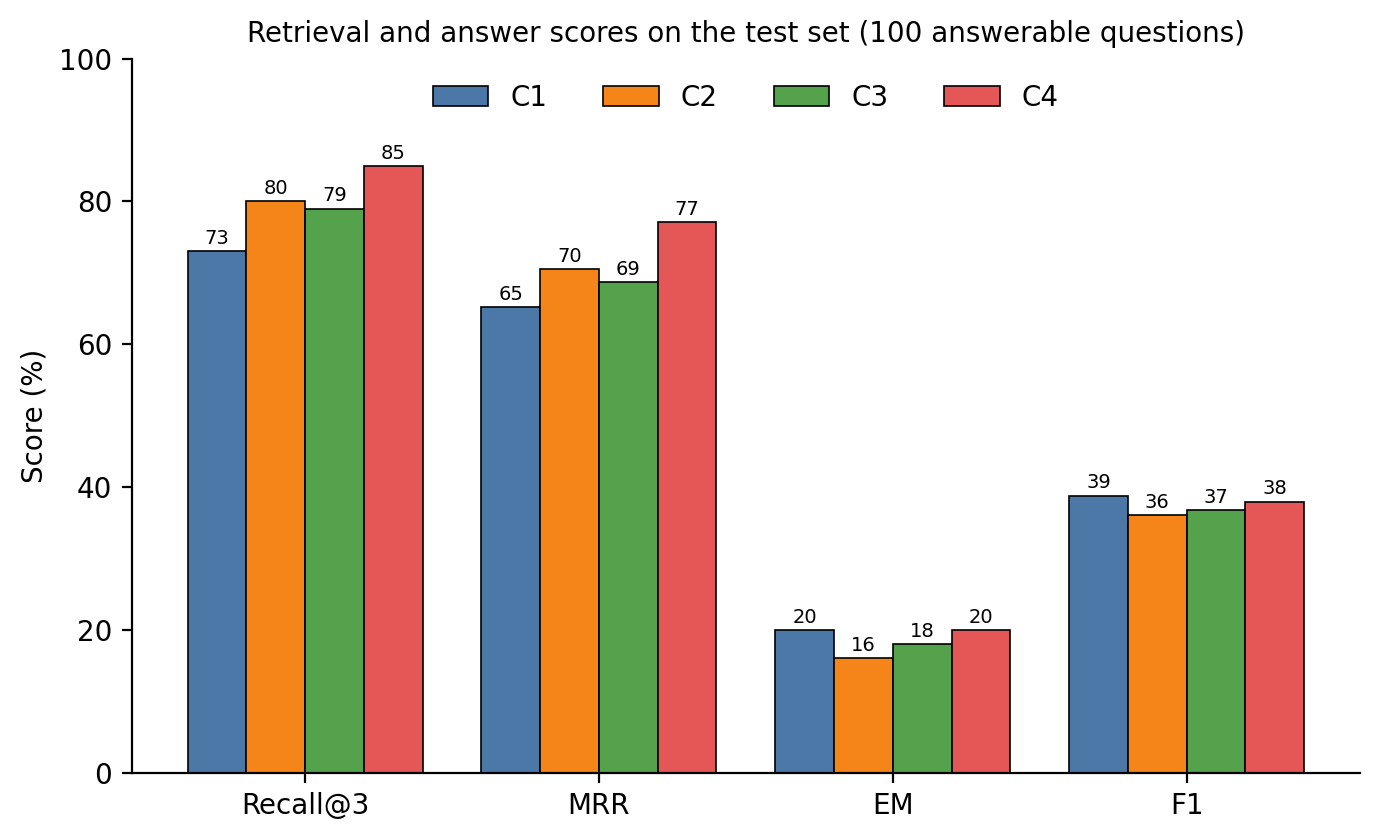

In [9]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Recall@3", "MRR", "EM", "F1"]
colors = ["#4C78A8", "#F58518", "#54A24B", "#E45756"]  

x = np.arange(len(metrics))
w = 0.2
fig, ax = plt.subplots(figsize=(7, 4.3), dpi=200)

for i, row in df_sum.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - 1.5) * w, vals, w, label=row["Condition"].split("_")[0],
                  color=colors[i], edgecolor="black", linewidth=0.6)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}", ha="center", fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.set_title("Retrieval and answer scores on the test set (100 answerable questions)", fontsize=10)
ax.legend(ncol=4, loc="upper center", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("rag_outputs/fig1_scores.png")
plt.show()